# Лабораторная работа №2. Regularization и KNN

- **Часть A** — L1 / L2 / ElasticNet в линейной (Bike Sharing) и логистической (Spaceship Titanic) регрессии из ЛР1.
- **Часть B** — KNN-классификация, Dry Bean, target `Class`.
- **Часть C** — KNN-регрессия, Seoul Bike Sharing, target `Rented Bike Count`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../../data")
VAL_SIZE = 0.2
TEST_SIZE = 0.2
RANDOM_STATE = 42

## Общие инструменты

Собственный train/validation/test split и метрики.

In [2]:
def train_val_test_split_own(n_samples, val_size=0.2, test_size=0.2, random_state=42):
    # test — первый кусок перестановки: при том же seed совпадает с test из ЛР1
    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(n_samples)

    n_test = int(round(n_samples * test_size))
    n_val = int(round(n_samples * val_size))
    return shuffled[n_test + n_val:], shuffled[n_test:n_test + n_val], shuffled[:n_test]

In [3]:
def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot)


def accuracy(y_true, y_pred):
    return float(np.mean(y_true == y_pred))


def f1(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    return float(2 * tp / (2 * tp + fp + fn))


def log_loss(y_true, y_proba):
    y_proba = np.clip(y_proba, 1e-15, 1 - 1e-15)
    return float(-np.mean(y_true * np.log(y_proba) + (1 - y_true) * np.log(1 - y_proba)))

def confusion_matrix_multi(y_true, y_pred, classes):
    # строка — истинный класс, столбец — предсказанный
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    for i, true_class in enumerate(classes):
        for j, pred_class in enumerate(classes):
            matrix[i, j] = np.sum((y_true == true_class) & (y_pred == pred_class))
    return matrix


def macro_f1(y_true, y_pred, classes):
    # F1 каждого класса «один против всех», затем простое среднее
    matrix = confusion_matrix_multi(y_true, y_pred, classes)
    tp = np.diag(matrix)
    return float(np.mean(2 * tp / (matrix.sum(axis=1) + matrix.sum(axis=0))))

# Часть A. Regularization

К loss добавляется штраф за величину весов, к градиенту по весам — производная штрафа.
Bias не штрафуется. Все 4 варианта — один класс с параметрами `l1` и `l2`:

| вариант | штраф | добавка к `dw` |
|---|---|---|
| без регуляризации | 0 | 0 |
| L1 | λ₁·Σ\|w\| | λ₁·sign(w) |
| L2 | λ₂·Σw² | 2λ₂·w |
| ElasticNet | λ₁·Σ\|w\| + λ₂·Σw² | λ₁·sign(w) + 2λ₂·w |

## Модели с регуляризацией

In [4]:
def penalty(w, l1, l2):
    return l1 * np.sum(np.abs(w)) + l2 * np.sum(w ** 2)


def penalty_grad(w, l1, l2):
    return l1 * np.sign(w) + 2 * l2 * w

In [5]:
class LinearRegression:

    def __init__(self, learning_rate=0.05, epochs=10000, l1=0.0, l2=0.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l1 = l1
        self.l2 = l2

        self.w = None
        self.b = None
        self.history_ = []  # MSE + штраф на train

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history_ = []

        for _ in range(self.epochs):
            error = self.predict(X) - y
            self.history_.append(float(np.mean(error ** 2)) + penalty(self.w, self.l1, self.l2))

            dw = 2 / n_samples * (X.T @ error) + penalty_grad(self.w, self.l1, self.l2)
            db = 2 * float(np.mean(error))

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        return X @ self.w + self.b

In [6]:
class LogisticRegression:

    def __init__(self, learning_rate=0.1, epochs=2000, threshold=0.5, l1=0.0, l2=0.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.threshold = threshold
        self.l1 = l1
        self.l2 = l2

        self.w = None
        self.b = None
        self.history_ = []  # BCE + штраф на train

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history_ = []

        for _ in range(self.epochs):
            p = self.predict_proba(X)
            error = p - y
            self.history_.append(log_loss(y, p) + penalty(self.w, self.l1, self.l2))

            dw = (X.T @ error) / n_samples + penalty_grad(self.w, self.l1, self.l2)
            db = float(np.mean(error))

            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        return self._sigmoid(X @ self.w + self.b)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(float)

## Подбор λ и сравнение вариантов

Одинаковые split, preprocessing, `learning_rate`, `epochs` и нулевые начальные веса — различается только штраф.
Для каждого варианта перебирается сетка λ: обучение на train, оценка на validation, остаётся лучшая.
Test в подборе не участвует. Почти нулевой вес — меньше 1% от максимального по модулю веса той же модели.

In [7]:
def make_grids(l1_values, l2_values):
    elastic_net = []
    for l1 in l1_values:
        for l2 in l2_values:
            elastic_net.append((l1, l2))

    return {
        "без регуляризации": [(0.0, 0.0)],
        "L1": [(l1, 0.0) for l1 in l1_values],
        "L2": [(0.0, l2) for l2 in l2_values],
        "ElasticNet": elastic_net,
    }


def plot_variants(models, ylabel):
    for name, model in models.items():
        label = f"{name} (λ1={model.l1:g}, λ2={model.l2:g})"
        if name in ("L1", "ElasticNet"):
            plt.plot(model.history_, "--", label=label)  # пунктир поверх толстой линии — видны обе при совпадении
        else:
            plt.plot(model.history_, lw=4, alpha=0.4, label=label)

    final = [model.history_[-1] for model in models.values()]
    plt.ylim(min(final) * 0.97, max(final) * 1.08)  # масштаб плато: стартовый loss на порядки выше
    plt.title("Loss (с штрафом) по эпохам, 4 варианта с лучшими λ")
    plt.xlabel("эпоха")
    plt.ylabel(ylabel)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

## Linear Regression: Bike Sharing

In [8]:
TARGET_LIN = "cnt"
LEARNING_RATE_LIN = 0.05
EPOCHS_LIN = 10000

DROP_LIN = ["casual", "registered", "instant", "dteday"]  # leakage и служебные, как в ЛР1
NUMERIC_LIN = ["temp", "atemp", "hum", "windspeed"]
BINARY_LIN = ["yr", "holiday", "workingday"]
CATEGORICAL_LIN = ["season", "mnth", "weekday", "weathersit"]

L1_GRID_LIN = [0.01, 0.1, 1, 10, 100]
L2_GRID_LIN = [0.01, 0.1, 1, 10]  # при λ2 >= 1/lr = 20 множитель (1 - 2·lr·λ2) <= -1, спуск расходится

In [9]:
class Preprocessor:
    # стандартизация числовых, бинарные как есть, one-hot без первого уровня; статистики — по train

    def __init__(self, numeric, binary, categorical):
        self.numeric = list(numeric)
        self.binary = list(binary)
        self.categorical = list(categorical)

        self.levels_ = {}
        self.mean_ = None
        self.std_ = None

    def fit(self, df):
        for col in self.categorical:
            self.levels_[col] = np.sort(df[col].unique())[1:]

        values = df[self.numeric].to_numpy(dtype=float)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        return self

    def transform(self, df):
        numeric = (df[self.numeric].to_numpy(dtype=float) - self.mean_) / self.std_
        binary = df[self.binary].to_numpy(dtype=float)
        dummies = [(df[col].to_numpy()[:, None] == self.levels_[col][None, :]).astype(float)
                   for col in self.categorical]
        return np.hstack([numeric, binary] + dummies)

In [10]:
df_lin = pd.read_csv(DATA_DIR / "bike_sharing/day.csv")
X_df_lin = df_lin.drop(columns=DROP_LIN + [TARGET_LIN])
y_lin = df_lin[TARGET_LIN].to_numpy(dtype=float)

train_idx, val_idx, test_idx = train_val_test_split_own(len(X_df_lin), VAL_SIZE, TEST_SIZE, RANDOM_STATE)
prep_lin = Preprocessor(NUMERIC_LIN, BINARY_LIN, CATEGORICAL_LIN).fit(X_df_lin.iloc[train_idx])

X_train_lin = prep_lin.transform(X_df_lin.iloc[train_idx])
X_val_lin = prep_lin.transform(X_df_lin.iloc[val_idx])
X_test_lin = prep_lin.transform(X_df_lin.iloc[test_idx])
y_train_lin, y_val_lin, y_test_lin = y_lin[train_idx], y_lin[val_idx], y_lin[test_idx]

print(f"train {X_train_lin.shape}, val {X_val_lin.shape}, test {X_test_lin.shape}")

train (439, 29), val (146, 29), test (146, 29)


In [11]:
grids_lin = make_grids(L1_GRID_LIN, L2_GRID_LIN)
models_lin = {}

for name, pairs in grids_lin.items():
    best_rmse = np.inf
    for l1, l2 in pairs:
        model = LinearRegression(LEARNING_RATE_LIN, EPOCHS_LIN, l1=l1, l2=l2)
        model.fit(X_train_lin, y_train_lin)

        val_rmse = rmse(y_val_lin, model.predict(X_val_lin))
        if val_rmse < best_rmse:
            best_rmse = val_rmse
            models_lin[name] = model

### Loss по эпохам

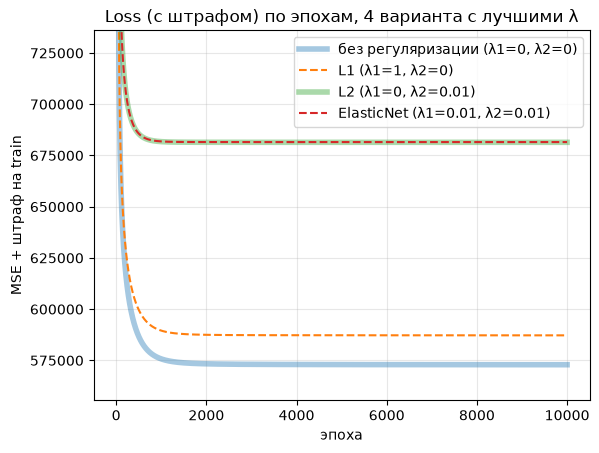

In [12]:
plot_variants(models_lin, "MSE + штраф на train")

### Метрики и веса

In [13]:
rows = {}
for name, model in models_lin.items():
    pred_val = model.predict(X_val_lin)
    pred_test = model.predict(X_test_lin)
    w = np.abs(model.w)

    rows[name] = {
        "λ1": model.l1,
        "λ2": model.l2,
        "RMSE val": rmse(y_val_lin, pred_val),
        "RMSE test": rmse(y_test_lin, pred_test),
        "MAE test": mae(y_test_lin, pred_test),
        "R2 test": r2(y_test_lin, pred_test),
        "Σ|w|": w.sum(),
        "почти нулевых": int(np.sum(w < 0.01 * w.max())),
        "всего весов": len(w),
    }

pd.DataFrame.from_dict(rows, orient="index").round(3)

,λ1,λ2,RMSE val,RMSE test,MAE test,R2 test,Σ|w|,почти нулевых,всего весов
без регуляризации,0.00,0.00,821.788,710.169,542.435,0.846,14609.266,0,29
L1,1.00,0.00,821.381,711.617,544.898,0.846,14003.891,3,29
L2,0.00,0.01,861.572,723.277,561.189,0.841,11427.835,0,29
ElasticNet,0.01,0.01,861.580,723.288,561.201,0.841,11425.541,0,29


## Logistic Regression: Spaceship Titanic

In [14]:
TARGET_LOG = "Transported"
LEARNING_RATE_LOG = 0.1
EPOCHS_LOG = 2000

DROP_LOG = ["PassengerId", "Name", "Cabin"]
SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
NUMERIC_LOG = ["Age"] + SPEND
BINARY_LOG = ["CryoSleep", "VIP"]
CATEGORICAL_LOG = ["HomePlanet", "Destination", "Deck", "Side"]

L1_GRID_LOG = [0.0001, 0.001, 0.01, 0.1, 1]
L2_GRID_LOG = [0.0001, 0.001, 0.01, 0.1, 1]


def split_cabin(df):
    parts = df["Cabin"].str.split("/", expand=True)  # палуба/номер/сторона
    return parts[0], parts[2]

In [15]:
class PreprocessorB:
    # импутация, log1p трат, стандартизация числовых, one-hot категорий; статистики — по train

    def __init__(self, numeric, binary, categorical, spend):
        self.numeric = list(numeric)
        self.binary = list(binary)
        self.categorical = list(categorical)
        self.spend = list(spend)

        self.modes_ = {}
        self.medians_ = {}
        self.levels_ = {}
        self.mean_ = None
        self.std_ = None

    def fit(self, df):
        for col in self.binary + self.categorical:
            self.modes_[col] = df[col].mode()[0]

        # медиана трат — только по бодрствующим: у спящих траты всегда 0
        awake = df[df["CryoSleep"] == False]
        for col in self.numeric:
            self.medians_[col] = (awake[col] if col in self.spend else df[col]).median()

        filled = self._impute(df)
        for col in self.categorical:
            self.levels_[col] = np.sort(filled[col].unique())[1:]

        values = self._numeric_matrix(filled)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        return self

    def _impute(self, df):
        # пропуск трат у пассажира в криосне — 0, у бодрствующего — медиана бодрствующих
        out = df.copy()
        for col in self.binary + self.categorical:
            out[col] = out[col].fillna(self.modes_[col])

        in_cryo = out["CryoSleep"] == True
        for col in self.spend:
            fill = pd.Series(np.where(in_cryo, 0.0, self.medians_[col]), index=out.index)
            out[col] = out[col].fillna(fill)

        out["Age"] = out["Age"].fillna(self.medians_["Age"])
        return out

    def _numeric_matrix(self, filled):
        values = filled[self.numeric].to_numpy(dtype=float)
        spend_idx = [self.numeric.index(col) for col in self.spend]
        values[:, spend_idx] = np.log1p(values[:, spend_idx])
        return values

    def transform(self, df):
        filled = self._impute(df)
        numeric = (self._numeric_matrix(filled) - self.mean_) / self.std_
        binary = filled[self.binary].to_numpy(dtype=float)
        dummies = [(filled[col].to_numpy()[:, None] == self.levels_[col][None, :]).astype(float)
                   for col in self.categorical]
        return np.hstack([numeric, binary] + dummies)

In [16]:
df_log = pd.read_csv(DATA_DIR / "spaceship_titanic/train.csv")
deck, side = split_cabin(df_log)
X_df_log = df_log.drop(columns=DROP_LOG + [TARGET_LOG]).assign(Deck=deck, Side=side)
y_log = df_log[TARGET_LOG].to_numpy(dtype=float)

train_idx, val_idx, test_idx = train_val_test_split_own(len(X_df_log), VAL_SIZE, TEST_SIZE, RANDOM_STATE)
prep_log = PreprocessorB(NUMERIC_LOG, BINARY_LOG, CATEGORICAL_LOG, SPEND).fit(X_df_log.iloc[train_idx])

X_train_log = prep_log.transform(X_df_log.iloc[train_idx])
X_val_log = prep_log.transform(X_df_log.iloc[val_idx])
X_test_log = prep_log.transform(X_df_log.iloc[test_idx])
y_train_log, y_val_log, y_test_log = y_log[train_idx], y_log[val_idx], y_log[test_idx]

print(f"train {X_train_log.shape}, val {X_val_log.shape}, test {X_test_log.shape}")

train (5215, 20), val (1739, 20), test (1739, 20)


In [17]:
grids_log = make_grids(L1_GRID_LOG, L2_GRID_LOG)
models_log = {}

for name, pairs in grids_log.items():
    best_log_loss = np.inf
    for l1, l2 in pairs:
        model = LogisticRegression(LEARNING_RATE_LOG, EPOCHS_LOG, l1=l1, l2=l2)
        model.fit(X_train_log, y_train_log)

        val_log_loss = log_loss(y_val_log, model.predict_proba(X_val_log))
        if val_log_loss < best_log_loss:
            best_log_loss = val_log_loss
            models_log[name] = model

### Loss по эпохам

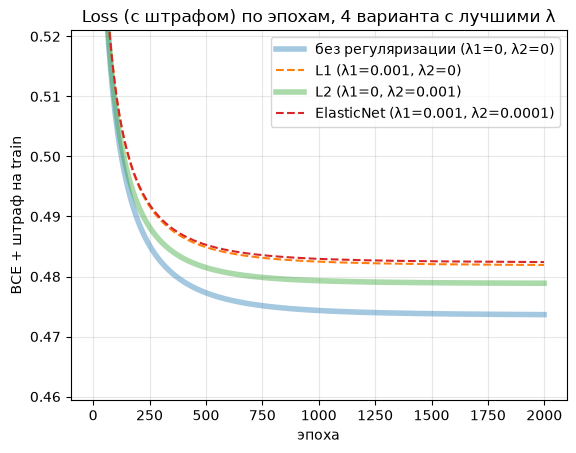

In [18]:
plot_variants(models_log, "BCE + штраф на train")

### Метрики и веса

In [19]:
rows = {}
for name, model in models_log.items():
    pred_test = model.predict(X_test_log)
    w = np.abs(model.w)

    rows[name] = {
        "λ1": model.l1,
        "λ2": model.l2,
        "LogLoss val": log_loss(y_val_log, model.predict_proba(X_val_log)),
        "LogLoss test": log_loss(y_test_log, model.predict_proba(X_test_log)),
        "Accuracy test": accuracy(y_test_log, pred_test),
        "F1 test": f1(y_test_log, pred_test),
        "Σ|w|": w.sum(),
        "почти нулевых": int(np.sum(w < 0.01 * w.max())),
        "всего весов": len(w),
    }

pd.DataFrame.from_dict(rows, orient="index").round(4)

,λ1,λ2,LogLoss val,LogLoss test,Accuracy test,F1 test,Σ|w|,почти нулевых,всего весов
без регуляризации,0.000,0.0000,0.4877,0.4796,0.7780,0.7827,8.6686,1,20
L1,0.001,0.0000,0.4873,0.4809,0.7815,0.7853,7.7263,2,20
L2,0.000,0.0010,0.4875,0.4806,0.7815,0.7853,8.0364,2,20
ElasticNet,0.001,0.0001,0.4873,0.4810,0.7815,0.7853,7.6723,2,20


## Вывод

Регуляризация в обеих моделях почти не повлияла на качество, потому что модели не были переобучены: ошибки на train
и на новых данных близки (линейная RMSE 757 / 822 / 710 на train / val / test, логистическая Accuracy 0.783 / 0.769 / 0.778),
а подбор по validation выбрал самые маленькие λ из сетки. В линейной регрессии L1 осталась на уровне модели без
регуляризации (RMSE val 821.4 против 821.8), а L2 и ElasticNet ухудшили результат (861.6) даже при λ₂ = 0.01.
В логистической регрессии все четыре варианта практически равны (Accuracy test 0.778–0.782).

На весах проявилось различие методов: L2 уменьшила все веса без зануления (у линейной Σ|w| 14 609 → 11 428),
L1 занулила слабые признаки (3 из 29 у линейной, 2 из 20 у логистической), ElasticNet повторил ту составляющую,
у которой λ больше. Регуляризация была бы полезна при переобучении — когда признаков много, данных мало
и на train модель заметно лучше, чем на validation.

# Часть B. KNN Classification

In [20]:
TARGET_BEAN = "Class"

## Dry Bean: загрузка и исследование

In [21]:
df_bean = pd.read_csv(DATA_DIR / "dry_bean/Dry_Bean_Dataset.csv")
features = df_bean.drop(columns=TARGET_BEAN)

duplicated = df_bean[df_bean.duplicated()]
print(f"размер {df_bean.shape[0]}x{df_bean.shape[1]} | пропусков {int(df_bean.isna().sum().sum())} | "
      f"дубликатов {len(duplicated)} (класс {', '.join(duplicated[TARGET_BEAN].unique())})")

counts = df_bean[TARGET_BEAN].value_counts()
print("классы:", ", ".join(f"{name} {count}" for name, count in counts.items()))

corr = np.triu(features.corr().abs().to_numpy(), k=1)  # каждая пара признаков один раз
n_features = features.shape[1]
print(f"пар признаков с корреляцией > 0.95: {int(np.sum(corr > 0.95))} из {n_features * (n_features - 1) // 2}")

размер 13611x17 | пропусков 0 | дубликатов 68 (класс HOROZ)
классы: DERMASON 3546, SIRA 2636, SEKER 2027, HOROZ 1928, CALI 1630, BARBUNYA 1322, BOMBAY 522
пар признаков с корреляцией > 0.95: 15 из 120


## Формирование X и y

Дубликаты удаляются до split, чтобы одно и то же зерно не попало одновременно в train и test.

In [22]:
df_bean = df_bean.drop_duplicates()
X_bean = df_bean.drop(columns=TARGET_BEAN).to_numpy(dtype=float)
y_bean = df_bean[TARGET_BEAN].to_numpy()
classes_bean = np.unique(y_bean)

print(f"X {X_bean.shape}, y {y_bean.shape}, классов {len(classes_bean)}")

X (13543, 16), y (13543,), классов 7


## Split и стандартизация

Среднее и std считаются только по train. Нестандартизированные копии (`_raw`) нужны для сравнения без scaling.

In [23]:
train_idx, val_idx, test_idx = train_val_test_split_own(len(X_bean), VAL_SIZE, TEST_SIZE, RANDOM_STATE)

X_train_bean_raw, X_val_bean_raw, X_test_bean_raw = X_bean[train_idx], X_bean[val_idx], X_bean[test_idx]
y_train_bean, y_val_bean, y_test_bean = y_bean[train_idx], y_bean[val_idx], y_bean[test_idx]

mean_bean = X_train_bean_raw.mean(axis=0)
std_bean = X_train_bean_raw.std(axis=0)
X_train_bean = (X_train_bean_raw - mean_bean) / std_bean
X_val_bean = (X_val_bean_raw - mean_bean) / std_bean
X_test_bean = (X_test_bean_raw - mean_bean) / std_bean

print(f"train {X_train_bean.shape}, val {X_val_bean.shape}, test {X_test_bean.shape}")
print(f"доля BOMBAY (самый редкий класс): train {np.mean(y_train_bean == 'BOMBAY'):.3f}, "
      f"val {np.mean(y_val_bean == 'BOMBAY'):.3f}, test {np.mean(y_test_bean == 'BOMBAY'):.3f}")

train (8125, 16), val (2709, 16), test (2709, 16)
доля BOMBAY (самый редкий класс): train 0.039, val 0.044, test 0.033


## Класс KNN

`fit` запоминает train. `predict` для каждого объекта считает расстояния до всего train, берёт k ближайших
и отдаёт самый частый класс (`classification`) или среднее таргета (`regression`).

In [24]:
class KNN:

    def __init__(self, k=5, task="classification", distance="euclidean"):
        self.k = k
        self.task = task
        self.distance = distance

        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def _distances(self, x):
        diff = self.X_train - x
        if self.distance == "euclidean":
            return np.sqrt(np.sum(diff ** 2, axis=1))
        return np.sum(np.abs(diff), axis=1)

    def _predict_one(self, x):
        nearest = np.argsort(self._distances(x))[:self.k]
        neighbors = self.y_train[nearest]

        if self.task == "regression":
            return neighbors.mean()

        labels, counts = np.unique(neighbors, return_counts=True)
        return labels[np.argmax(counts)]  # при ничьей — первый по алфавиту

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])

In [25]:
knn = KNN(k=5).fit(X_train_bean, y_train_bean)
print(f"k=5, euclidean, со scaling: accuracy val {accuracy(y_val_bean, knn.predict(X_val_bean)):.4f}")

k=5, euclidean, со scaling: accuracy val 0.9243


## Подбор k, расстояние и scaling

Для каждого сочетания scaling и расстояния k подбирается по Macro F1 на validation — классы несбалансированы.

In [26]:
K_VALUES = [1, 3, 5, 7, 11, 15, 25]

data_variants = {
    "со scaling": (X_train_bean, X_val_bean),
    "без scaling": (X_train_bean_raw, X_val_bean_raw),
}

f1_by_k = {}
for scaling, (X_train, X_val) in data_variants.items():
    for distance in ["euclidean", "manhattan"]:
        scores = []
        for k in K_VALUES:
            pred = KNN(k=k, distance=distance).fit(X_train, y_train_bean).predict(X_val)
            scores.append(macro_f1(y_val_bean, pred, classes_bean))
        f1_by_k[f"{distance}, {scaling}"] = scores

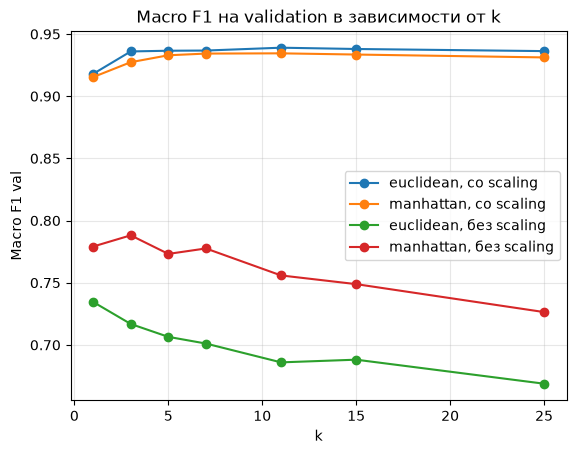

In [27]:
for name, scores in f1_by_k.items():
    plt.plot(K_VALUES, scores, marker="o", label=name)

plt.title("Macro F1 на validation в зависимости от k")
plt.xlabel("k")
plt.ylabel("Macro F1 val")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [28]:
rows = {}
for name, scores in f1_by_k.items():
    best = int(np.argmax(scores))
    rows[name] = {"лучший k": K_VALUES[best], "Macro F1 val": round(scores[best], 4)}

pd.DataFrame.from_dict(rows, orient="index")

,лучший k,Macro F1 val
"euclidean, со scaling",11,0.9390
"manhattan, со scaling",11,0.9345
"euclidean, без scaling",1,0.7346
"manhattan, без scaling",3,0.7881


## Итоговая модель на test

Scaling однозначно лучше, поэтому из вариантов со scaling берётся расстояние и k с наибольшим Macro F1 на validation.

In [29]:
best_f1 = -1
for distance in ["euclidean", "manhattan"]:
    scores = f1_by_k[f"{distance}, со scaling"]
    if max(scores) > best_f1:
        best_f1 = max(scores)
        best_distance = distance
        best_k = K_VALUES[int(np.argmax(scores))]

final_knn = KNN(k=best_k, distance=best_distance).fit(X_train_bean, y_train_bean)
pred_test_bean = final_knn.predict(X_test_bean)

print(f"k={best_k}, {best_distance}, со scaling | test: Accuracy {accuracy(y_test_bean, pred_test_bean):.4f}, "
      f"Macro F1 {macro_f1(y_test_bean, pred_test_bean, classes_bean):.4f}")

k=11, euclidean, со scaling | test: Accuracy 0.9225, Macro F1 0.9360


### Confusion matrix (test)

Строка — истинный сорт, столбец — предсказанный.

In [30]:
matrix = confusion_matrix_multi(y_test_bean, pred_test_bean, classes_bean)
pd.DataFrame(matrix, index=classes_bean, columns=classes_bean)

,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
BARBUNYA,230,0,17,0,1,3,6
BOMBAY,0,89,0,0,0,0,0
CALI,5,0,303,0,7,0,2
DERMASON,0,0,0,676,1,11,50
HOROZ,0,0,5,3,345,0,11
SEKER,3,0,0,4,0,388,16
SIRA,0,0,1,53,8,3,468


## Вывод по части B

Главный фактор качества KNN на Dry Bean — scaling: со стандартизацией Macro F1 на validation 0.939 (Euclidean)
и 0.935 (Manhattan), без неё 0.735 и 0.788, потому что без scaling расстояние определяют площадь и выпуклая площадь
(десятки тысяч), а признаки формы (около 1) почти не влияют. Со scaling Euclidean и Manhattan практически равны.
При k = 1 качество ниже (0.918) — модель зависит от одного соседа, с k = 3 кривая выходит на плато, лучший k = 11;
без scaling качество с ростом k только падает.

Итоговая модель (k = 11, Euclidean, со scaling) на test: Accuracy 0.9225, Macro F1 0.936. Macro F1 выше accuracy,
то есть редкие сорта распознаются не хуже частых: самый редкий BOMBAY угадан полностью (89 из 89).
Основные ошибки — между похожими сортами: DERMASON и SIRA (50 и 53 ошибки в обе стороны) и BARBUNYA → CALI (17).

# Часть C. KNN Regression

In [31]:
TARGET_SEOUL = "Rented Bike Count"

NUMERIC_SEOUL = ["Hour", "Temperature(°C)", "Humidity(%)", "Wind speed (m/s)", "Visibility (10m)",
                 "Dew point temperature(°C)", "Solar Radiation (MJ/m2)", "Rainfall(mm)", "Snowfall (cm)"]
SEASONS = ["Spring", "Summer", "Autumn", "Winter"]

## Seoul Bike Sharing: загрузка и исследование

In [32]:
df_seoul = pd.read_csv(DATA_DIR / "seoul_sharing/SeoulBikeData.csv")
target = df_seoul[TARGET_SEOUL]

print(f"размер {df_seoul.shape[0]}x{df_seoul.shape[1]} | пропусков {int(df_seoul.isna().sum().sum())} | "
      f"дубликатов {int(df_seoul.duplicated().sum())} | таргет {target.min()}..{target.max()}, среднее {target.mean():.0f}")

closed = df_seoul[df_seoul["Functioning Day"] == "No"]
print(f"нерабочих часов (Functioning Day = No): {len(closed)}, прокат в них всегда {closed[TARGET_SEOUL].max()}")

by_hour = df_seoul.groupby("Hour")[TARGET_SEOUL].mean()
print(f"средний прокат: 4 ч {by_hour[4]:.0f}, 8 ч {by_hour[8]:.0f}, 13 ч {by_hour[13]:.0f}, 18 ч {by_hour[18]:.0f}")

corr = df_seoul[NUMERIC_SEOUL + [TARGET_SEOUL]].corr()[TARGET_SEOUL].drop(TARGET_SEOUL).sort_values(ascending=False)
print("корреляция с таргетом:", ", ".join(f"{name} {value:.2f}" for name, value in corr.items()))

размер 8760x14 | пропусков 0 | дубликатов 0 | таргет 0..3556, среднее 705
нерабочих часов (Functioning Day = No): 295, прокат в них всегда 0
средний прокат: 4 ч 133, 8 ч 1016, 13 ч 733, 18 ч 1503
корреляция с таргетом: Temperature(°C) 0.54, Hour 0.41, Dew point temperature(°C) 0.38, Solar Radiation (MJ/m2) 0.26, Visibility (10m) 0.20, Wind speed (m/s) 0.12, Rainfall(mm) -0.12, Snowfall (cm) -0.14, Humidity(%) -0.20


## Формирование X и y

Нерабочие часы убираются: прокат в них всегда 0, прогноз известен без модели.
Из `Date` берётся признак выходного дня, `Holiday` — 0/1, `Seasons` — one-hot по всем 4 сезонам
(для KNN без отбрасывания уровня, чтобы все сезоны были на одинаковом расстоянии друг от друга).

In [33]:
df_seoul = df_seoul[df_seoul["Functioning Day"] == "Yes"]
dates = pd.to_datetime(df_seoul["Date"], format="%d/%m/%Y")

X_df_seoul = df_seoul[NUMERIC_SEOUL].copy()
X_df_seoul["Holiday"] = (df_seoul["Holiday"] == "Holiday").astype(float)
X_df_seoul["Weekend"] = (dates.dt.dayofweek >= 5).astype(float)
for season in SEASONS:
    X_df_seoul[season] = (df_seoul["Seasons"] == season).astype(float)

X_seoul = X_df_seoul.to_numpy(dtype=float)
y_seoul = df_seoul[TARGET_SEOUL].to_numpy(dtype=float)

print(f"X {X_seoul.shape}, y {y_seoul.shape} | признаки: {', '.join(X_df_seoul.columns)}")

X (8465, 15), y (8465,) | признаки: Hour, Temperature(°C), Humidity(%), Wind speed (m/s), Visibility (10m), Dew point temperature(°C), Solar Radiation (MJ/m2), Rainfall(mm), Snowfall (cm), Holiday, Weekend, Spring, Summer, Autumn, Winter


## Split и стандартизация

Стандартизуются только числовые признаки (первые столбцы X), по среднему и std train.
Бинарные и one-hot остаются 0/1. Нестандартизированные копии (`_raw`) — для сравнения без scaling.

In [34]:
train_idx, val_idx, test_idx = train_val_test_split_own(len(X_seoul), VAL_SIZE, TEST_SIZE, RANDOM_STATE)

X_train_seoul_raw, X_val_seoul_raw, X_test_seoul_raw = X_seoul[train_idx], X_seoul[val_idx], X_seoul[test_idx]
y_train_seoul, y_val_seoul, y_test_seoul = y_seoul[train_idx], y_seoul[val_idx], y_seoul[test_idx]

n_numeric = len(NUMERIC_SEOUL)
mean_seoul = X_train_seoul_raw[:, :n_numeric].mean(axis=0)
std_seoul = X_train_seoul_raw[:, :n_numeric].std(axis=0)

X_train_seoul, X_val_seoul, X_test_seoul = X_train_seoul_raw.copy(), X_val_seoul_raw.copy(), X_test_seoul_raw.copy()
X_train_seoul[:, :n_numeric] = (X_train_seoul_raw[:, :n_numeric] - mean_seoul) / std_seoul
X_val_seoul[:, :n_numeric] = (X_val_seoul_raw[:, :n_numeric] - mean_seoul) / std_seoul
X_test_seoul[:, :n_numeric] = (X_test_seoul_raw[:, :n_numeric] - mean_seoul) / std_seoul

print(f"train {X_train_seoul.shape}, val {X_val_seoul.shape}, test {X_test_seoul.shape}")

train (5079, 15), val (1693, 15), test (1693, 15)


## Подбор k, расстояние и scaling

Тот же перебор, что в части B, но KNN в режиме `regression`, критерий — RMSE на validation.

In [35]:
data_variants = {
    "со scaling": (X_train_seoul, X_val_seoul),
    "без scaling": (X_train_seoul_raw, X_val_seoul_raw),
}

rmse_by_k = {}
for scaling, (X_train, X_val) in data_variants.items():
    for distance in ["euclidean", "manhattan"]:
        scores = []
        for k in K_VALUES:
            pred = KNN(k=k, task="regression", distance=distance).fit(X_train, y_train_seoul).predict(X_val)
            scores.append(rmse(y_val_seoul, pred))
        rmse_by_k[f"{distance}, {scaling}"] = scores

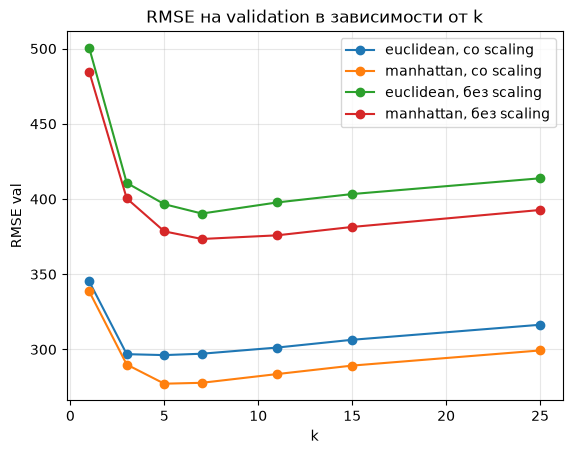

In [36]:
for name, scores in rmse_by_k.items():
    plt.plot(K_VALUES, scores, marker="o", label=name)

plt.title("RMSE на validation в зависимости от k")
plt.xlabel("k")
plt.ylabel("RMSE val")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [37]:
rows = {}
for name, scores in rmse_by_k.items():
    best = int(np.argmin(scores))
    rows[name] = {"лучший k": K_VALUES[best], "RMSE val": round(scores[best], 1)}

pd.DataFrame.from_dict(rows, orient="index")

,лучший k,RMSE val
"euclidean, со scaling",5,296.2
"manhattan, со scaling",5,277.2
"euclidean, без scaling",7,390.3
"manhattan, без scaling",7,373.4


## Итоговая модель на test и baseline

Из вариантов со scaling берётся расстояние и k с наименьшим RMSE на validation.
Baseline всегда предсказывает средний прокат по train.

In [38]:
best_rmse = np.inf
for distance in ["euclidean", "manhattan"]:
    scores = rmse_by_k[f"{distance}, со scaling"]
    if min(scores) < best_rmse:
        best_rmse = min(scores)
        best_distance = distance
        best_k = K_VALUES[int(np.argmin(scores))]

final_knn_seoul = KNN(k=best_k, task="regression", distance=best_distance).fit(X_train_seoul, y_train_seoul)
pred_test_seoul = final_knn_seoul.predict(X_test_seoul)
baseline_test_seoul = np.full(len(y_test_seoul), y_train_seoul.mean())

for name, pred in [(f"KNN (k={best_k}, {best_distance})", pred_test_seoul),
                   (f"baseline (всегда {y_train_seoul.mean():.0f})", baseline_test_seoul)]:
    print(f"{name}: MAE {mae(y_test_seoul, pred):.0f}, RMSE {rmse(y_test_seoul, pred):.0f}, "
          f"R2 {r2(y_test_seoul, pred):.3f}")

KNN (k=5, manhattan): MAE 173, RMSE 269, R2 0.829
baseline (всегда 737): MAE 519, RMSE 650, R2 -0.000


## Вывод по части C

KNN-регрессия хорошо описывает прокат велосипедов: на test MAE 173, RMSE 269, R² 0.829 против MAE 519, RMSE 650
и R² 0 у baseline, который всегда предсказывает среднее 737, — ошибка меньше в 3 раза. Зависимость проката от часа
нелинейная (ночью 133, утренний пик 1016, вечерний 1503), и KNN её улавливает за счёт похожих часов с похожей погодой.

Лучший вариант — Manhattan со scaling, k = 5 (RMSE val 277.2 против 296.2 у Euclidean). Без scaling ошибка больше
на ~100 (373–390), потому что расстояние определяют признаки с большими числами, например видимость (до 2000).
По k видна U-кривая: при k = 1 ошибка высокая (около 340, модель повторяет одного соседа), минимум при k = 5–7,
дальше ошибка растёт — прогноз сглаживается к среднему.